# Multimodal Sentiment Classification of Internet Memes (Memotion 7k)
**COMP1013 Multi-Modal Data Analysis - Project 2.2 - Group Fusion Force**

This notebook reproduces every result, table and figure in the report. It classifies memes as
**negative / neutral / positive** from the meme **image** and its **text**, and compares:

| Family | Models |
|---|---|
| Baselines | majority class, zero-shot CLIP (no training), logistic-regression probes |
| Unimodal | image-only MLP (CLIP), text-only MLP (CLIP text), text-only MLP (RoBERTa) |
| **Early fusion** | concatenation MLP, concatenation + interaction terms MLP, CLIP image + RoBERTa MLP |
| **Late fusion** | validation-tuned weighted average of image-only and text-only probabilities |
| **Attention fusion** | per-meme attention weights over modalities (course weeks 4-5), CLIP and RoBERTa text variants |

Uncertainty is estimated with Monte Carlo dropout (course week 5) and used for selective prediction.

**How to run**
1. Download the dataset zip from Kaggle: https://www.kaggle.com/datasets/williamscott701/memotion-dataset-7k
2. Put the zip (or the unzipped folder) inside `data/` next to this notebook - or set `DATA_PATH` below.
3. `pip install -r requirements.txt`, then *Run All*. On an Apple-silicon Mac it uses the MPS GPU automatically.

Everything is written to `outputs/` (figures, tables, `results_summary.json`) and zipped into
`outputs_for_report.zip` at the end. Encoder features are cached in `outputs/cache/`, so a second run
skips feature extraction.

## 1. Setup and configuration

In [1]:
import json
import shutil
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import Config, get_device, set_seed, environment_info
from src import data as D, features as F, models as M, evaluate as E, plots as P

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
P.set_style()

import kagglehub
DATA_PATH = kagglehub.dataset_download("williamscott701/memotion-dataset-7k")
print("Path to dataset files:", DATA_PATH)

cfg = Config(data_path=DATA_PATH)
cfg.make_dirs()
DEVICE = get_device()
CLASSES = list(cfg.classes)
ENV = environment_info()
print("Encoder device:", DEVICE, "| classifier-head device:", cfg.train_device)
print(json.dumps(ENV, indent=1))

Path to dataset files: /Users/habel/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1
Encoder device: mps | classifier-head device: cpu
{
 "python": "3.14.6",
 "platform": "macOS-26.6-arm64-arm-64bit-Mach-O",
 "processor": "arm",
 "torch": "2.14.1",
 "sklearn": "1.9.0",
 "accelerator": "mps",
 "transformers": "5.19.0"
}


## 2. Data loading and quality assessment
The loader accepts the Kaggle zip or folder, merges the five-point `overall_sentiment` into three
classes, and builds one text per meme (**corrected OCR → raw OCR → `[no text]` placeholder**).
Every image is fully decoded once to catch missing, truncated or corrupt files.

In [2]:
labels_csv, images_dir = D.locate_dataset(cfg.data_path)
print("labels:", labels_csv, "\nimages:", images_dir)

df = D.load_labels(labels_csv, images_dir)
if cfg.max_samples:
    from sklearn.model_selection import train_test_split
    keep, _ = train_test_split(np.arange(len(df)), train_size=cfg.max_samples, stratify=df["label"], random_state=0)
    df = df.iloc[np.sort(keep)].reset_index(drop=True)

t0 = time.perf_counter()
df = D.inspect_images(df)
print(f"Inspected {len(df)} images in {time.perf_counter() - t0:.1f}s")

QUALITY = D.quality_summary(df)
display(pd.Series({k: v for k, v in QUALITY.items() if not isinstance(v, (dict, list))}, name="value").to_frame())
print("3-class counts:", QUALITY["sentiment_3_counts"], "| %:", QUALITY["sentiment_3_pct"])
print("Text source:", QUALITY["text_source_counts"])
print("Image formats:", QUALITY["image_formats"], "| modes:", QUALITY["image_modes"])
if QUALITY["unreadable_examples"]:
    display(pd.DataFrame(QUALITY["unreadable_examples"]))

labels: /Users/habel/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1/memotion_dataset_7k/labels.csv 
images: /Users/habel/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1/memotion_dataset_7k/images
Inspected 6992 images in 2.6s


,value
n_rows,6992.0
n_unique_image_names,6992.0
ocr_missing,161.0
corrected_missing,5.0
unreadable_images,1.0
animated_images,1.0
exact_duplicate_images,49.0
duplicate_texts,138.0
width_median,500.0
height_median,500.0


3-class counts: {'negative': 631, 'neutral': 2201, 'positive': 4160} | %: {'negative': 9.0, 'neutral': 31.5, 'positive': 59.5}
Text source: {'corrected': 6987, 'placeholder': 4, 'ocr': 1}
Image formats: {'JPEG': 5314, 'PNG': 1675, 'GIF': 3} | modes: {'RGB': 5468, 'P': 1248, 'RGBA': 243, 'L': 31, 'CMYK': 2}


,image_name,error
0,image_5119.png,OSError: image file is truncated


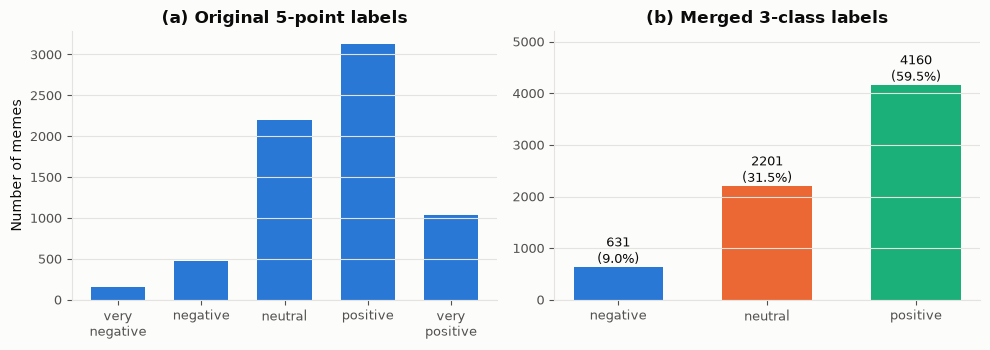

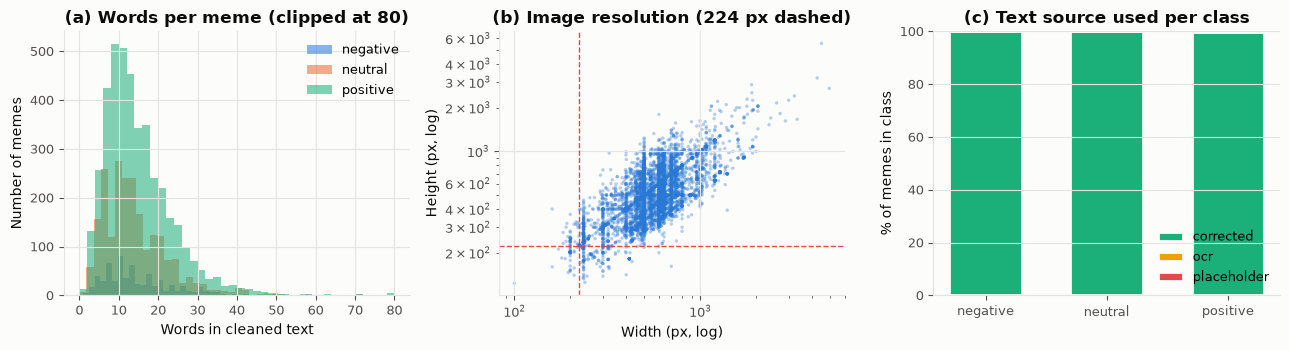

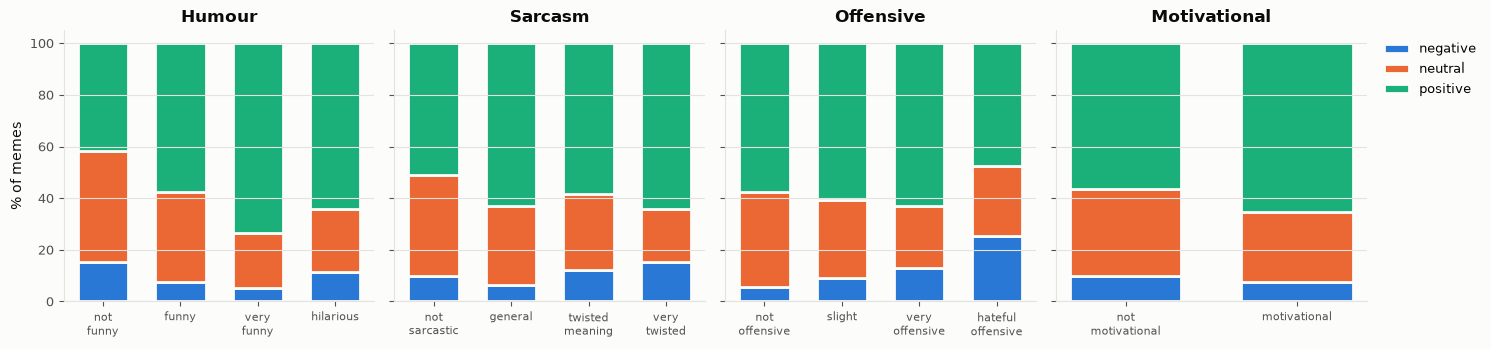

In [3]:
P.plot_label_distribution(df, cfg.fig_dir / "fig01_label_distribution.png", CLASSES); plt.show()
P.plot_data_quality(df, cfg.fig_dir / "fig02_data_quality.png", CLASSES); plt.show()
P.plot_aux_vs_sentiment(df, cfg.fig_dir / "fig03_aux_labels_vs_sentiment.png", D.AUX_ORDERS, CLASSES); plt.show()

## 3. Preprocessing
**Text**: lowercase, remove URLs and meme-generator watermarks (e.g. `imgflip.com`), drop special
characters, collapse whitespace; truncated by the tokenizers (77 CLIP tokens, 128 RoBERTa tokens).

**Images**: GIFs → first frame, transparent PNGs composited on white, converted to RGB, resized and
centre-cropped to 224×224, normalised with CLIP statistics. Training memes also get
`n_aug_views` augmented views (random resized crop 80-100% + colour jitter, **no flips** because
flipping mirrors the burned-in caption).

**Change from proposal**: memes with no usable text are *kept* with a `[no text]` placeholder instead
of being removed, so the image can still carry the prediction (removing them would bias the test set
towards memes with readable captions). Only unreadable images are removed.

In [4]:
examples = df.loc[df["text_source"] != "placeholder", ["text_corrected", "text"]].head(5)
display(examples.rename(columns={"text_corrected": "original (corrected OCR)", "text": "cleaned"}))

n_before = len(df)
df = df[df["readable"]].reset_index(drop=True)
REMOVED_UNREADABLE = n_before - len(df)
print(f"Removed {REMOVED_UNREADABLE} unreadable images -> {len(df)} memes used")

df["split"] = D.make_splits(df, cfg.split_ratios, cfg.split_seed)
split_tab = pd.crosstab(df["split"], df["sentiment"]).reindex(index=["train", "val", "test"], columns=CLASSES)
split_tab["total"] = split_tab.sum(1)
display(split_tab)
split_tab.to_csv(cfg.table_dir / "split_counts.csv")

tr, va, te = (df["split"] == s for s in ("train", "val", "test"))
y_tr, y_va, y_te = df.loc[tr, "label"].values, df.loc[va, "label"].values, df.loc[te, "label"].values
df_te = df[te].reset_index(drop=True)

,original (corrected OCR),cleaned
0,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,look there my friend lightyear now all sohalik...
1,The best of #10 YearChallenge! Completed in le...,the best of 10 yearchallenge! completed in les...
2,Sam Thorne @Strippin ( Follow Follow Saw every...,sam thorne strippin follow follow saw everyone...
3,10 Year Challenge - Sweet Dee Edition,10 year challenge sweet dee edition
4,10 YEAR CHALLENGE WITH NO FILTER 47 Hilarious ...,10 year challenge with no filter 47 hilarious ...


Removed 1 unreadable images -> 6991 memes used


/var/folders/87/7brlyzb56jz795j7197hzt8m0000gn/T/ipykernel_9505/2955183704.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  split_tab["total"] = split_tab.sum(1)


sentiment,negative,neutral,positive,total
split,,,,
train,442,1540,2911,4893
val,95,330,624,1049
test,94,331,624,1049


## 4. Feature extraction (frozen encoders)
* **CLIP ViT-B/32** image and text encoders (512-d each, L2-normalised). CLIP was trained on 400M
  image-text pairs, so its image and text vectors live in a shared space - a strong prior for memes,
  where meaning comes from how picture and caption relate.
* **RoBERTa-base** mean-pooled token embeddings (768-d) as a stronger *language-only* text encoder.

Encoders stay frozen and features are computed once (cached), which keeps the whole study well inside
a laptop/free-GPU budget and lets every classifier be trained over 5 seeds.

In [5]:
feats = F.extract_all(df, tr.values, cfg, DEVICE)
CLIP_ENC, _ = feats.pop("encoders")
TIMINGS, ENC_PARAMS = feats.pop("timings_sec"), feats.pop("encoder_params")
for k, v in feats.items():
    print(f"{k:14s} {v.shape}")
print("Extraction seconds:", {k: round(v, 1) for k, v in TIMINGS.items()})

Loading openai/clip-vit-base-patch32 and roberta-base on mps ...


[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


clip_img       (6991, 512)
clip_img_aug   (4893, 3, 512)
clip_txt       (6991, 512)
roberta_txt    (6991, 768)
Extraction seconds: {'clip_img': 51.5, 'clip_img_aug0': 36.6, 'clip_img_aug1': 36.8, 'clip_txt': 13.3, 'roberta_txt': 26.0}


### 4.1 Near-duplicate check (leakage and label consistency)
Memes are often re-posted or share a template. If a test meme is almost identical to a training meme,
scores can be inflated. Near-duplicates with *different* labels also show how subjective the labels are.

In [6]:
img_all, txt_all, rob_all = feats["clip_img"], feats["clip_txt"], feats["roberta_txt"]
ND = E.near_duplicates(img_all[tr.values], img_all[te.values], y_tr, y_te, cfg.near_dup_threshold)
print(f"Test memes with a near-duplicate image in train (cos >= {cfg.near_dup_threshold}): "
      f"{ND['n_test_near_dup']} ({ND['pct_test_near_dup']:.1f}%)")
print(f"Label agreement with that training near-duplicate: {ND['label_agreement_pct']:.1f}%")

Test memes with a near-duplicate image in train (cos >= 0.95): 12 (1.1%)
Label agreement with that training near-duplicate: 66.7%


## 5. Experiments
All neural heads: 1 hidden layer (256, GELU, dropout 0.3, input dropout 0.1), AdamW (lr 1e-3,
weight decay 1e-4), class-weighted cross-entropy, batch 128, up to 80 epochs, early stopping on
**validation macro-F1** (patience 10). Each is trained with 5 seeds; we report mean ± std on the
fixed test split. Model selection never looks at the test set.

In [7]:
def scale_mod(train_3d, *others):
    s = M.PartScaler().fit([train_3d])
    return (s.transform([train_3d])[0], *[s.transform([o])[0] for o in others])

IMG = scale_mod(feats["clip_img_aug"], img_all[va.values], img_all[te.values])
TXT = scale_mod(txt_all[tr.values][:, None, :], txt_all[va.values], txt_all[te.values])
ROB = scale_mod(rob_all[tr.values][:, None, :], rob_all[va.values], rob_all[te.values])

RUNS, HIST, FAMILY, PROBA = {}, {}, {}, {}

def record(name, family, seed, p_tr, p_va, p_te, **extra):
    RUNS.setdefault(name, []).append({
        "seed": seed,
        "train": E.compute_metrics(y_tr, p_tr, CLASSES) if p_tr is not None else {},
        "val": E.compute_metrics(y_va, p_va, CLASSES),
        "test": E.compute_metrics(y_te, p_te, CLASSES),
        **extra,
    })
    FAMILY[name] = family
    PROBA.setdefault(name, {})[seed] = {"val": p_va, "test": p_te}

def run_mlp(name, family, mods, mode="concat", weighted=True, use_aug=True, seeds=None):
    tr_parts = [m[0] for m in mods]
    va_parts = [m[1] for m in mods]
    te_parts = [m[2] for m in mods]
    tr0 = [p[:, 0] for p in tr_parts]
    for seed in (seeds or cfg.seeds):
        r = M.train_mlp(tr_parts, y_tr, va_parts, y_va, cfg, seed, mode, weighted, use_aug)
        t0 = time.perf_counter()
        p_te = M.predict_proba(r.model, te_parts, cfg, mode)
        infer = time.perf_counter() - t0
        record(name, family, seed, M.predict_proba(r.model, tr0, cfg, mode),
               M.predict_proba(r.model, va_parts, cfg, mode), p_te,
               best_epoch=r.best_epoch + 1, train_seconds=r.train_seconds,
               infer_seconds=infer, n_params=r.n_params)
        if seed == cfg.seeds[0]:
            HIST[name] = r.history
            PROBA[name]["model"] = r.model
    m = pd.DataFrame([x["test"] for x in RUNS[name]])
    print(f"{name:32s} test macro-F1 {m.macro_f1.mean():.3f} ± {m.macro_f1.std():.3f}")

### 5.1 Baselines (no learning / linear)

In [8]:
prior = np.bincount(y_tr, minlength=3) / len(y_tr)
maj = lambda n: np.tile(np.eye(3)[prior.argmax()], (n, 1))
record("Majority class", "Baseline", 0, maj(len(y_tr)), maj(len(y_va)), maj(len(y_te)))

PROMPTS = F.zero_shot_prompt_embeddings(CLIP_ENC, CLASSES, cfg)
def zs(idx, use_text):
    e = img_all[idx] + (txt_all[idx] if use_text else 0)
    e = e / np.linalg.norm(e, axis=1, keepdims=True)
    return M.zero_shot_proba(e, PROMPTS)
for nm, use_text in (("Zero-shot CLIP (image)", False), ("Zero-shot CLIP (image+text)", True)):
    record(nm, "Baseline", 0, zs(tr.values, use_text), zs(va.values, use_text), zs(te.values, use_text))

LR_INFO = {}
for nm, fam, mods in (("LogReg image (CLIP)", "Image only", [IMG]),
                      ("LogReg text (CLIP)", "Text only", [TXT]),
                      ("LogReg early fusion (concat)", "Early fusion", [IMG, TXT])):
    Xtr = M.combine([m[0][:, 0] for m in mods]); Xva = M.combine([m[1] for m in mods]); Xte = M.combine([m[2] for m in mods])
    clf, info = M.train_logreg(Xtr, y_tr, Xva, y_va)
    LR_INFO[nm] = info
    record(nm, fam, 0, clf.predict_proba(Xtr), clf.predict_proba(Xva), clf.predict_proba(Xte),
           train_seconds=info["train_seconds"], n_params=int(clf.coef_.size + clf.intercept_.size))
    print(f"{nm:32s} C={info['C']}  test macro-F1 {RUNS[nm][0]['test']['macro_f1']:.3f}")

LogReg image (CLIP)              C=0.01  test macro-F1 0.308
LogReg text (CLIP)               C=0.1  test macro-F1 0.312
LogReg early fusion (concat)     C=1.0  test macro-F1 0.342


### 5.2 Unimodal MLPs

In [9]:
run_mlp("Image only (CLIP)", "Image only", [IMG])
run_mlp("Text only (CLIP)", "Text only", [TXT])
run_mlp("Text only (RoBERTa)", "Text only", [ROB])

Image only (CLIP)                test macro-F1 0.327 ± 0.006
Text only (CLIP)                 test macro-F1 0.345 ± 0.015
Text only (RoBERTa)              test macro-F1 0.340 ± 0.008


### 5.3 Technique 1 - Early fusion
* **Concat**: `[image ; text]` (1024-d) → MLP.
* **Concat + interactions**: `[i ; t ; i⊙t ; |i−t|]` (2048-d). The element-wise product and absolute
  difference let the head see *agreement or contrast* between picture and caption directly, which is
  how sarcasm in memes often works (a happy image with a bitter caption).
* **CLIP image + RoBERTa**: tests whether a stronger language encoder helps once fused.

In [10]:
run_mlp("Early fusion (concat)", "Early fusion", [IMG, TXT], mode="concat")
run_mlp("Early fusion (interaction)", "Early fusion", [IMG, TXT], mode="interact")
run_mlp("Early fusion (CLIP img + RoBERTa)", "Early fusion", [IMG, ROB], mode="concat")

Early fusion (concat)            test macro-F1 0.335 ± 0.010
Early fusion (interaction)       test macro-F1 0.321 ± 0.009
Early fusion (CLIP img + RoBERTa) test macro-F1 0.337 ± 0.018


### 5.4 Technique 2 - Late fusion
Image-only and text-only heads (same seed) are combined as `p = w·p_image + (1−w)·p_text`; `w` is
picked on the validation set from a 0-1 grid (step 0.05). This is decision-level fusion: each modality
is modelled independently and only their predictions interact.

Late fusion (CLIP img + CLIP txt) image weight w = 0.60 ± 0.39 | test macro-F1 0.336 ± 0.007
Late fusion (CLIP img + RoBERTa) image weight w = 0.12 ± 0.08 | test macro-F1 0.340 ± 0.007


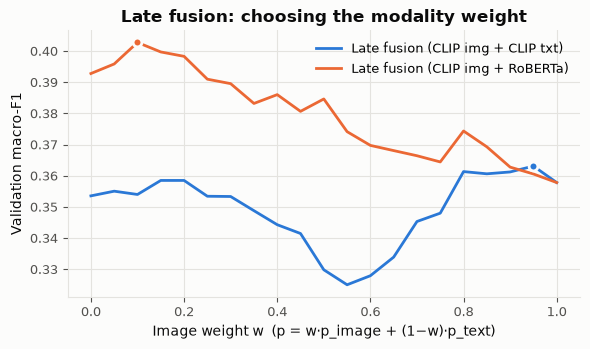

In [11]:
LF_W, LF_CURVES = {}, {}
for nm, a, b in (("Late fusion (CLIP img + CLIP txt)", "Image only (CLIP)", "Text only (CLIP)"),
                 ("Late fusion (CLIP img + RoBERTa)", "Image only (CLIP)", "Text only (RoBERTa)")):
    LF_W[nm] = []
    for seed in cfg.seeds:
        pa, pb = PROBA[a][seed], PROBA[b][seed]
        w, curve = M.tune_late_fusion(pa["val"], pb["val"], y_va, cfg.late_fusion_grid)
        LF_W[nm].append(w)
        if seed == cfg.seeds[0]:
            LF_CURVES[nm] = curve
        tra = M.predict_proba(PROBA[a]["model"], [IMG[0][:, 0]], cfg) if seed == cfg.seeds[0] else None
        trb = M.predict_proba(PROBA[b]["model"], [(TXT if "CLIP txt" in nm else ROB)[0][:, 0]], cfg) if seed == cfg.seeds[0] else None
        p_tr = M.late_fuse(tra, trb, w) if tra is not None else None
        record(nm, "Late fusion", seed, p_tr, M.late_fuse(pa["val"], pb["val"], w),
               M.late_fuse(pa["test"], pb["test"], w), image_weight=w)
    m = pd.DataFrame([x["test"] for x in RUNS[nm]])
    print(f"{nm:32s} image weight w = {np.mean(LF_W[nm]):.2f} ± {np.std(LF_W[nm]):.2f} | "
          f"test macro-F1 {m.macro_f1.mean():.3f} ± {m.macro_f1.std():.3f}")
P.plot_late_fusion_curve(np.array(cfg.late_fusion_grid), LF_CURVES, cfg.fig_dir / "fig07_late_fusion_weight.png"); plt.show()

### 5.5 Technique 3 - Attention-gated fusion (weeks 4-5)
Each modality is projected to 256-d; a small attention network scores each modality **for every meme**
and the softmax weights mix them before the classifier:
`h_m = GELU(W_m x_m)`, `a = softmax_m(v·tanh(U h_m))`, `z = Σ a_m h_m`.
This sits between early fusion (one joint vector, no explicit weighting) and late fusion (one global
weight `w` for all memes), and the learned weights show which modality the model trusts per meme.

Attention fusion (CLIP img + CLIP txt) test macro-F1 0.340 ± 0.010
Attention fusion (CLIP img + RoBERTa) test macro-F1 0.322 ± 0.007


,mean_image_weight,std,pct_image_dominant
negative,0.470,0.369,47.872
neutral,0.444,0.373,42.900
positive,0.434,0.368,43.109


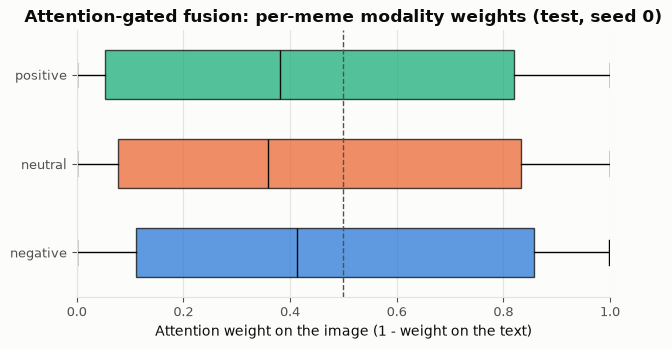

In [12]:
run_mlp("Attention fusion (CLIP img + CLIP txt)", "Attention fusion", [IMG, TXT], mode="gated")
run_mlp("Attention fusion (CLIP img + RoBERTa)", "Attention fusion", [IMG, ROB], mode="gated")
ATT = M.attention_weights(PROBA["Attention fusion (CLIP img + CLIP txt)"]["model"], [IMG[2], TXT[2]], cfg)
ATT_BY_CLASS = {c: ATT[y_te == k, 0] for k, c in enumerate(CLASSES)}
ATT_SUMMARY = pd.DataFrame({c: {"mean_image_weight": float(v.mean()), "std": float(v.std()),
                                "pct_image_dominant": float((v > 0.5).mean() * 100)} for c, v in ATT_BY_CLASS.items()}).T
display(ATT_SUMMARY)
ATT_SUMMARY.to_csv(cfg.table_dir / "attention_weights.csv")
P.plot_attention_weights(ATT_BY_CLASS, cfg.fig_dir / "fig15_attention_weights.png"); plt.show()

### 5.6 Ablations on early fusion
* no class weights (plain cross-entropy) - effect of the imbalance handling
* no image augmentation - effect of the cached augmented views
* modality removal at test time - each modality replaced by its training mean (0 after
  standardisation) to measure how much the fused model relies on it

In [13]:
run_mlp("EF ablation: no class weights", "Early fusion", [IMG, TXT], weighted=False)
run_mlp("EF ablation: no augmentation", "Early fusion", [IMG, TXT], use_aug=False)

ABL_REMOVE = []  # evaluated on the seed-0 early-fusion model
ef_model = PROBA["Early fusion (concat)"]["model"]
for label, parts in (("full input", [IMG[2], TXT[2]]),
                     ("image removed", [np.zeros_like(IMG[2]), TXT[2]]),
                     ("text removed", [IMG[2], np.zeros_like(TXT[2])])):
    p = M.predict_proba(ef_model, parts, cfg)
    ABL_REMOVE.append({"setting": label, **E.compute_metrics(y_te, p, CLASSES)})
ABL_REMOVE = pd.DataFrame(ABL_REMOVE).set_index("setting")
display(ABL_REMOVE[["accuracy", "macro_f1", "balanced_accuracy"]])
ABL_REMOVE.to_csv(cfg.table_dir / "ablation_modality_removal.csv")

EF ablation: no class weights    test macro-F1 0.329 ± 0.015
EF ablation: no augmentation     test macro-F1 0.338 ± 0.017


,accuracy,macro_f1,balanced_accuracy
setting,,,
full input,0.445,0.329,0.329
image removed,0.422,0.334,0.339
text removed,0.460,0.342,0.342


## 6. Evaluation
### 6.1 Main comparison (test set, mean ± std over seeds)

,family,macro_f1,accuracy,balanced_accuracy,weighted_f1,macro_auc,cohen_kappa,log_loss
model,,,,,,,,
Majority class,Baseline,0.249 ± 0.000,0.595 ± 0.000,0.333 ± 0.000,0.444 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,6.530 ± 0.000
Zero-shot CLIP (image),Baseline,0.305 ± 0.000,0.356 ± 0.000,0.342 ± 0.000,0.394 ± 0.000,0.500 ± 0.000,0.013 ± 0.000,1.120 ± 0.000
Zero-shot CLIP (image+text),Baseline,0.285 ± 0.000,0.308 ± 0.000,0.342 ± 0.000,0.349 ± 0.000,0.509 ± 0.000,0.012 ± 0.000,1.157 ± 0.000
LogReg image (CLIP),Image only,0.308 ± 0.000,0.354 ± 0.000,0.339 ± 0.000,0.383 ± 0.000,0.514 ± 0.000,-0.011 ± 0.000,1.164 ± 0.000
LogReg text (CLIP),Text only,0.312 ± 0.000,0.358 ± 0.000,0.342 ± 0.000,0.387 ± 0.000,0.515 ± 0.000,-0.005 ± 0.000,1.238 ± 0.000
LogReg early fusion (concat),Early fusion,0.342 ± 0.000,0.412 ± 0.000,0.357 ± 0.000,0.438 ± 0.000,0.511 ± 0.000,0.036 ± 0.000,1.907 ± 0.000
Image only (CLIP),Image only,0.327 ± 0.006,0.460 ± 0.022,0.329 ± 0.005,0.458 ± 0.013,0.494 ± 0.008,-0.006 ± 0.009,1.389 ± 0.140
Text only (CLIP),Text only,0.345 ± 0.015,0.473 ± 0.021,0.346 ± 0.014,0.472 ± 0.015,0.513 ± 0.009,0.018 ± 0.020,1.377 ± 0.144
Text only (RoBERTa),Text only,0.340 ± 0.008,0.489 ± 0.010,0.343 ± 0.008,0.483 ± 0.007,0.511 ± 0.010,0.033 ± 0.012,1.561 ± 0.188


Best fusion model (by validation macro-F1): Late fusion (CLIP img + RoBERTa) | best EF: Early fusion (CLIP img + RoBERTa) | best LF: Late fusion (CLIP img + RoBERTa) | best AF: Attention fusion (CLIP img + RoBERTa)


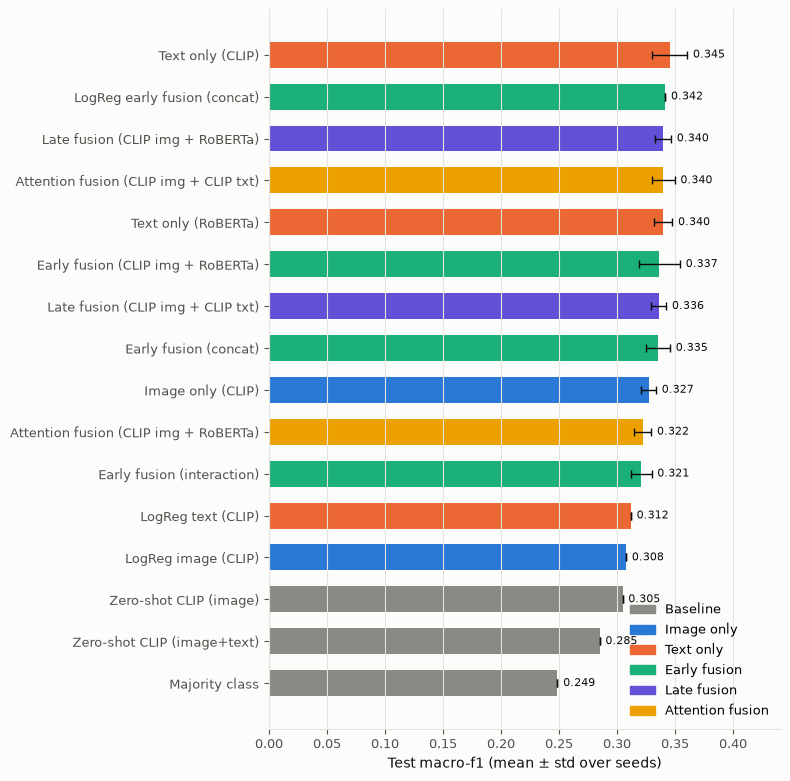

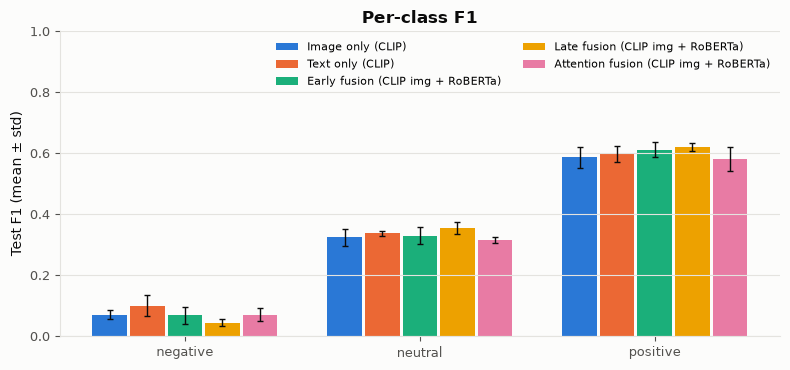

In [14]:
SUMMARY = E.summarise_runs(RUNS, "test")
MAIN = ["Majority class", "Zero-shot CLIP (image)", "Zero-shot CLIP (image+text)",
        "LogReg image (CLIP)", "LogReg text (CLIP)", "LogReg early fusion (concat)",
        "Image only (CLIP)", "Text only (CLIP)", "Text only (RoBERTa)",
        "Early fusion (concat)", "Early fusion (interaction)", "Early fusion (CLIP img + RoBERTa)",
        "Late fusion (CLIP img + CLIP txt)", "Late fusion (CLIP img + RoBERTa)",
        "Attention fusion (CLIP img + CLIP txt)", "Attention fusion (CLIP img + RoBERTa)"]
cols = ["macro_f1", "accuracy", "balanced_accuracy", "weighted_f1", "macro_auc", "cohen_kappa", "log_loss"]
table = pd.DataFrame({c: SUMMARY.loc[MAIN, f"{c}_mean"].map("{:.3f}".format) + " ± " +
                      SUMMARY.loc[MAIN, f"{c}_std"].map("{:.3f}".format) for c in cols})
table.insert(0, "family", [FAMILY[m] for m in MAIN])
display(table)
table.to_csv(cfg.table_dir / "table_main_results.csv")
SUMMARY.to_csv(cfg.table_dir / "summary_all_metrics.csv")

# best fusion model chosen on VALIDATION macro-F1, never on test
VAL_SUMMARY = E.summarise_runs(RUNS, "val")
fusion = [m for m in MAIN if FAMILY[m] in ("Early fusion", "Late fusion", "Attention fusion") and not m.startswith("LogReg")]
BEST_FUSION = VAL_SUMMARY.loc[fusion, "macro_f1_mean"].idxmax()
BEST_EF = VAL_SUMMARY.loc[[m for m in fusion if FAMILY[m] == "Early fusion"], "macro_f1_mean"].idxmax()
BEST_LF = VAL_SUMMARY.loc[[m for m in fusion if FAMILY[m] == "Late fusion"], "macro_f1_mean"].idxmax()
BEST_AF = VAL_SUMMARY.loc[[m for m in fusion if FAMILY[m] == "Attention fusion"], "macro_f1_mean"].idxmax()
print("Best fusion model (by validation macro-F1):", BEST_FUSION, "| best EF:", BEST_EF, "| best LF:", BEST_LF, "| best AF:", BEST_AF)

P.plot_model_comparison(SUMMARY.loc[MAIN], FAMILY, cfg.fig_dir / "fig04_model_comparison.png"); plt.show()
KEY = ["Image only (CLIP)", "Text only (CLIP)", BEST_EF, BEST_LF, BEST_AF]
P.plot_per_class_f1(SUMMARY, KEY, CLASSES, cfg.fig_dir / "fig05_per_class_f1.png"); plt.show()

### 6.2 Confusion matrices, confidence intervals and significance

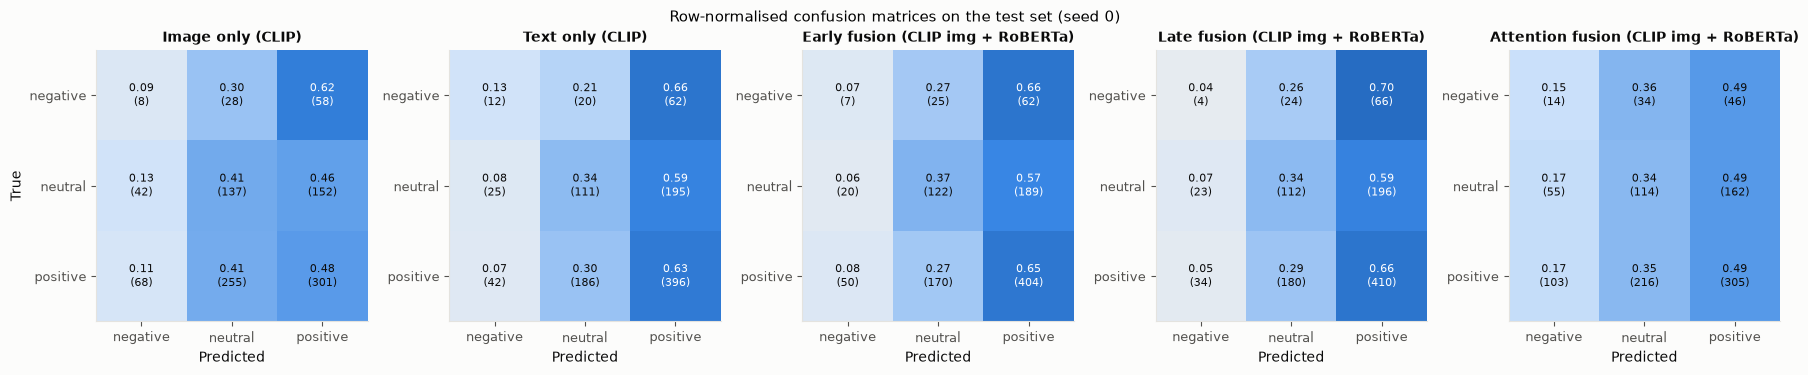

,macro_f1,ci_low,ci_high
Image only (CLIP),0.324,0.296,0.353
Text only (CLIP),0.367,0.338,0.398
Early fusion (CLIP img + RoBERTa),0.363,0.334,0.393
Late fusion (CLIP img + RoBERTa),0.344,0.318,0.371
Attention fusion (CLIP img + RoBERTa),0.323,0.297,0.350
Text only (RoBERTa),0.341,0.316,0.368


,a_right_b_wrong,a_wrong_b_right,p_value
Early fusion (CLIP img + RoBERTa) vs Late fusion (CLIP img + RoBERTa),160.0,153.0,7.346e-01
Attention fusion (CLIP img + RoBERTa) vs Early fusion (CLIP img + RoBERTa),120.0,220.0,6.415e-08
Attention fusion (CLIP img + RoBERTa) vs Text only (CLIP),168.0,254.0,3.309e-05
Late fusion (CLIP img + RoBERTa) vs Text only (CLIP),193.0,186.0,7.580e-01
Late fusion (CLIP img + RoBERTa) vs Image only (CLIP),264.0,184.0,1.829e-04


,mean_diff,std_diff,seeds_a_better,n_seeds
Early fusion (CLIP img + RoBERTa) - Late fusion (CLIP img + RoBERTa),-0.003,0.019,2.0,5.0
Attention fusion (CLIP img + RoBERTa) - Early fusion (CLIP img + RoBERTa),-0.015,0.020,1.0,5.0
Late fusion (CLIP img + RoBERTa) - Text only (CLIP),-0.006,0.012,2.0,5.0
Late fusion (CLIP img + RoBERTa) - Image only (CLIP),0.013,0.008,5.0,5.0


In [15]:
s0 = cfg.seeds[0]
pred = {m: PROBA[m][s0]["test"].argmax(1) if s0 in PROBA[m] else PROBA[m][0]["test"].argmax(1) for m in RUNS}
CMS = {m: E.confusion(y_te, pred[m]) for m in KEY}
P.plot_confusions(CMS, CLASSES, cfg.fig_dir / "fig06_confusion_matrices.png"); plt.show()

CI = pd.DataFrame({m: E.bootstrap_ci(y_te, pred[m], cfg.n_bootstrap) for m in KEY + ["Text only (RoBERTa)"]},
                  index=["macro_f1", "ci_low", "ci_high"]).T
display(CI)
CI.to_csv(cfg.table_dir / "bootstrap_ci_seed0.csv")

TESTS = {
    f"{BEST_EF} vs {BEST_LF}": E.mcnemar(y_te, pred[BEST_EF], pred[BEST_LF]),
    f"{BEST_AF} vs {BEST_EF}": E.mcnemar(y_te, pred[BEST_AF], pred[BEST_EF]),
    f"{BEST_AF} vs Text only (CLIP)": E.mcnemar(y_te, pred[BEST_AF], pred["Text only (CLIP)"]),
    f"{BEST_FUSION} vs Text only (CLIP)": E.mcnemar(y_te, pred[BEST_FUSION], pred["Text only (CLIP)"]),
    f"{BEST_FUSION} vs Image only (CLIP)": E.mcnemar(y_te, pred[BEST_FUSION], pred["Image only (CLIP)"]),
}
display(pd.DataFrame(TESTS).T)
pd.DataFrame(TESTS).T.to_csv(cfg.table_dir / "mcnemar_tests.csv")

# paired comparison across seeds (same seed, same split)
def seed_scores(m):
    return np.array([r["test"]["macro_f1"] for r in RUNS[m]])
PAIRED = {}
for a, b in ((BEST_EF, BEST_LF), (BEST_AF, BEST_EF), (BEST_FUSION, "Text only (CLIP)"), (BEST_FUSION, "Image only (CLIP)")):
    d = seed_scores(a) - seed_scores(b)
    PAIRED[f"{a} - {b}"] = {"mean_diff": float(d.mean()), "std_diff": float(d.std(ddof=1)),
                            "seeds_a_better": int((d > 0).sum()), "n_seeds": len(d)}
display(pd.DataFrame(PAIRED).T)

### 6.3 Overfitting assessment
Train vs validation vs test macro-F1 (train measured on original, non-augmented views) and the epoch
chosen by early stopping. A large train-test gap with an early best epoch indicates the head memorises
the frozen features quickly.

,train_macro_f1,val_macro_f1,test_macro_f1,train_test_gap,best_epoch_mean
model,,,,,
Image only (CLIP),0.947,0.362,0.327,0.619,23.4
Text only (CLIP),0.951,0.356,0.345,0.605,18.2
Text only (RoBERTa),0.984,0.381,0.340,0.644,21.8
Early fusion (concat),0.957,0.353,0.335,0.622,13.2
Early fusion (interaction),0.932,0.344,0.321,0.610,8.4
Early fusion (CLIP img + RoBERTa),0.950,0.372,0.337,0.614,13.4
Attention fusion (CLIP img + CLIP txt),0.946,0.359,0.340,0.607,14.0
Attention fusion (CLIP img + RoBERTa),0.905,0.377,0.322,0.583,10.8
EF ablation: no augmentation,0.875,0.358,0.338,0.538,10.8


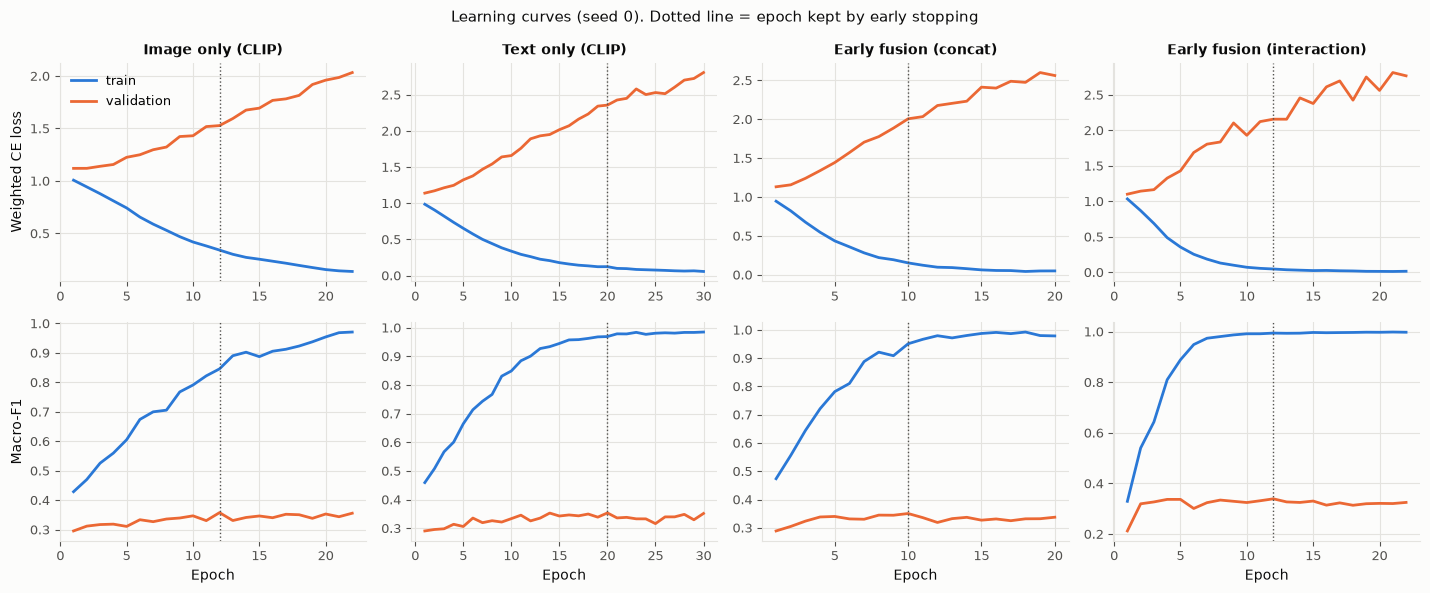

,macro_f1_mean,macro_f1_std,f1_negative_mean,balanced_accuracy_mean
model,,,,
Early fusion (concat),0.335,0.010,0.094,0.336
EF ablation: no class weights,0.329,0.015,0.047,0.337
EF ablation: no augmentation,0.338,0.017,0.108,0.342
Early fusion (interaction),0.321,0.009,0.055,0.327
Early fusion (CLIP img + RoBERTa),0.337,0.018,0.069,0.337


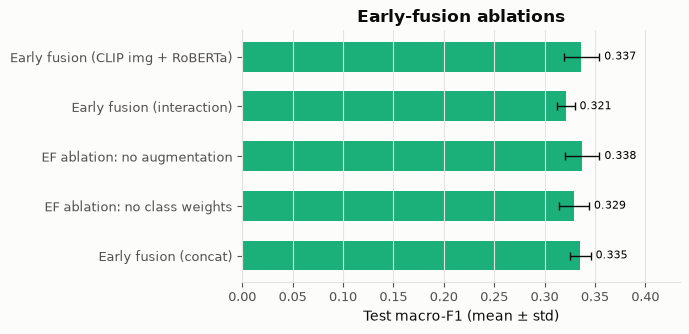

In [16]:
OVERFIT = []
for m in ["Image only (CLIP)", "Text only (CLIP)", "Text only (RoBERTa)", "Early fusion (concat)",
          "Early fusion (interaction)", "Early fusion (CLIP img + RoBERTa)", "Attention fusion (CLIP img + CLIP txt)",
          "Attention fusion (CLIP img + RoBERTa)", "EF ablation: no augmentation",
          "LogReg early fusion (concat)"]:
    rs = RUNS[m]
    trf = np.mean([r["train"]["macro_f1"] for r in rs]); vaf = np.mean([r["val"]["macro_f1"] for r in rs])
    tef = np.mean([r["test"]["macro_f1"] for r in rs])
    OVERFIT.append({"model": m, "train_macro_f1": trf, "val_macro_f1": vaf, "test_macro_f1": tef,
                    "train_test_gap": trf - tef,
                    "best_epoch_mean": np.mean([r.get("best_epoch", np.nan) for r in rs])})
OVERFIT = pd.DataFrame(OVERFIT).set_index("model")
display(OVERFIT)
OVERFIT.to_csv(cfg.table_dir / "overfitting.csv")
P.plot_learning_curves({k: HIST[k] for k in ["Image only (CLIP)", "Text only (CLIP)", "Early fusion (concat)",
                                             "Early fusion (interaction)"]},
                       cfg.fig_dir / "fig08_learning_curves.png"); plt.show()

ABL = SUMMARY.loc[["Early fusion (concat)", "EF ablation: no class weights", "EF ablation: no augmentation",
                   "Early fusion (interaction)", "Early fusion (CLIP img + RoBERTa)"],
                  ["macro_f1_mean", "macro_f1_std", "f1_negative_mean", "balanced_accuracy_mean"]]
display(ABL)
ABL.to_csv(cfg.table_dir / "ablation_early_fusion.csv")
P.plot_ablation(ABL, cfg.fig_dir / "fig09_ablation.png"); plt.show()

### 6.4 Efficiency
Encoders are frozen, so the expensive step is a single forward pass per meme; heads are tiny.

In [17]:
EFF = []
for m in list(dict.fromkeys(KEY + ["Text only (RoBERTa)", "Early fusion (interaction)", "Attention fusion (CLIP img + CLIP txt)",
                                  "Attention fusion (CLIP img + RoBERTa)", "LogReg early fusion (concat)"])):
    rs = RUNS[m]
    EFF.append({"model": m,
                "head_params": rs[0].get("n_params", np.nan),
                "train_seconds_mean": np.mean([r.get("train_seconds", np.nan) for r in rs]),
                "test_inference_ms_per_1000": 1000 * np.mean([r.get("infer_seconds", np.nan) for r in rs]) / len(y_te) * 1000})
EFF = pd.DataFrame(EFF).set_index("model")
display(EFF)
EFF.to_csv(cfg.table_dir / "efficiency.csv")
n_imgs = len(df) + cfg.n_aug_views * int(tr.sum())
print(f"Feature extraction on {DEVICE}: CLIP image {sum(v for k, v in TIMINGS.items() if k.startswith('clip_img')):.0f}s "
      f"for {n_imgs} images | CLIP text {TIMINGS['clip_txt']:.0f}s | RoBERTa {TIMINGS['roberta_txt']:.0f}s "
      f"(0 s means loaded from cache)")
print("Frozen encoder parameters:", {k: f"{v / 1e6:.0f}M" for k, v in ENC_PARAMS.items()})

,head_params,train_seconds_mean,test_inference_ms_per_1000
model,,,
Image only (CLIP),132099.0,1.106,0.754
Text only (CLIP),132099.0,0.876,0.656
Early fusion (CLIP img + RoBERTa),328707.0,1.306,1.272
Late fusion (CLIP img + RoBERTa),NaN,NaN,NaN
Attention fusion (CLIP img + RoBERTa),345476.0,1.693,2.074
Text only (RoBERTa),197635.0,1.198,0.830
Early fusion (interaction),525315.0,1.533,2.222
Attention fusion (CLIP img + CLIP txt),279940.0,1.687,1.765
LogReg early fusion (concat),3075.0,1.812,NaN


Feature extraction on mps: CLIP image 125s for 16777 images | CLIP text 13s | RoBERTa 26s (0 s means loaded from cache)
Frozen encoder parameters: {'clip': '151M', 'roberta': '125M'}


### 6.5 Uncertainty with Monte Carlo dropout (week 5)
Dropout is kept on at test time and 30 stochastic passes are averaged; predictive entropy measures how
unsure the model is. If uncertainty were informative, deferring the most uncertain memes to a human
reviewer would raise accuracy on the memes the model keeps (selective prediction).

,error_auroc,acc@100%,acc@90%,acc@80%,acc@70%,acc@60%,acc@50%,macro_f1_mc
Image only (CLIP),0.520,0.426,0.432,0.439,0.447,0.439,0.443,0.330
Text only (CLIP),0.557,0.488,0.498,0.504,0.510,0.523,0.532,0.358
Early fusion (concat),0.518,0.452,0.460,0.461,0.465,0.455,0.471,0.328
Attention fusion (CLIP img + CLIP txt),0.540,0.469,0.484,0.491,0.501,0.501,0.490,0.338


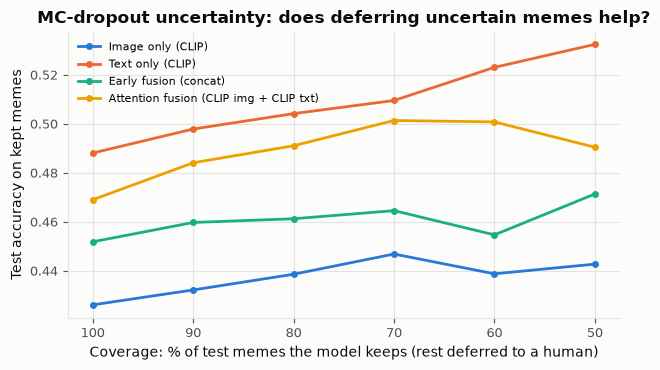

In [18]:
UNC, UNC_CURVES = {}, {}
for m, mode, parts in (("Image only (CLIP)", "concat", [IMG[2]]), ("Text only (CLIP)", "concat", [TXT[2]]),
                       ("Early fusion (concat)", "concat", [IMG[2], TXT[2]]),
                       ("Attention fusion (CLIP img + CLIP txt)", "gated", [IMG[2], TXT[2]])):
    p_mc, ent = M.mc_dropout_proba(PROBA[m]["model"], parts, cfg, mode, n_samples=30)
    rep = E.uncertainty_report(y_te, p_mc, ent)
    UNC[m] = {"error_auroc": rep["error_auroc"], **{f"acc@{int(r.coverage*100)}%": r.accuracy for r in rep["curve"].itertuples()},
              "macro_f1_mc": E.compute_metrics(y_te, p_mc, CLASSES)["macro_f1"]}
    UNC_CURVES[m] = rep["curve"]
UNC = pd.DataFrame(UNC).T
display(UNC)
UNC.to_csv(cfg.table_dir / "uncertainty_mc_dropout.csv")
P.plot_risk_coverage(UNC_CURVES, cfg.fig_dir / "fig14_mc_dropout_selective.png"); plt.show()

## 7. Analysis
### 7.1 Subgroup performance (bias check)
Performance across the auxiliary Memotion labels (sarcasm, humour, offensiveness, motivation) and
text availability. Groups are small, so we report accuracy alongside n.

,attribute,level,n,pct_negative,image_acc,image_macro_f1,text_acc,text_macro_f1,fusion_acc,fusion_macro_f1
0,humour,not_funny,236,18.220,0.381,0.313,0.407,0.356,0.407,0.326
1,humour,funny,377,6.897,0.424,0.323,0.480,0.354,0.477,0.332
2,humour,very_funny,321,4.673,0.461,0.311,0.567,0.336,0.598,0.359
3,humour,hilarious,115,8.696,0.417,0.333,0.522,0.399,0.504,0.290
4,sarcasm,not_sarcastic,242,11.570,0.483,0.370,0.467,0.380,0.483,0.340
5,sarcasm,general,537,5.959,0.421,0.304,0.508,0.349,0.514,0.342
6,sarcasm,twisted_meaning,210,11.429,0.367,0.299,0.529,0.382,0.486,0.332
7,sarcasm,very_twisted,60,16.667,0.433,0.353,0.367,0.298,0.517,0.365
8,offensive,not_offensive,415,6.506,0.451,0.332,0.477,0.348,0.530,0.368
9,offensive,slight,385,9.091,0.416,0.320,0.504,0.363,0.488,0.330


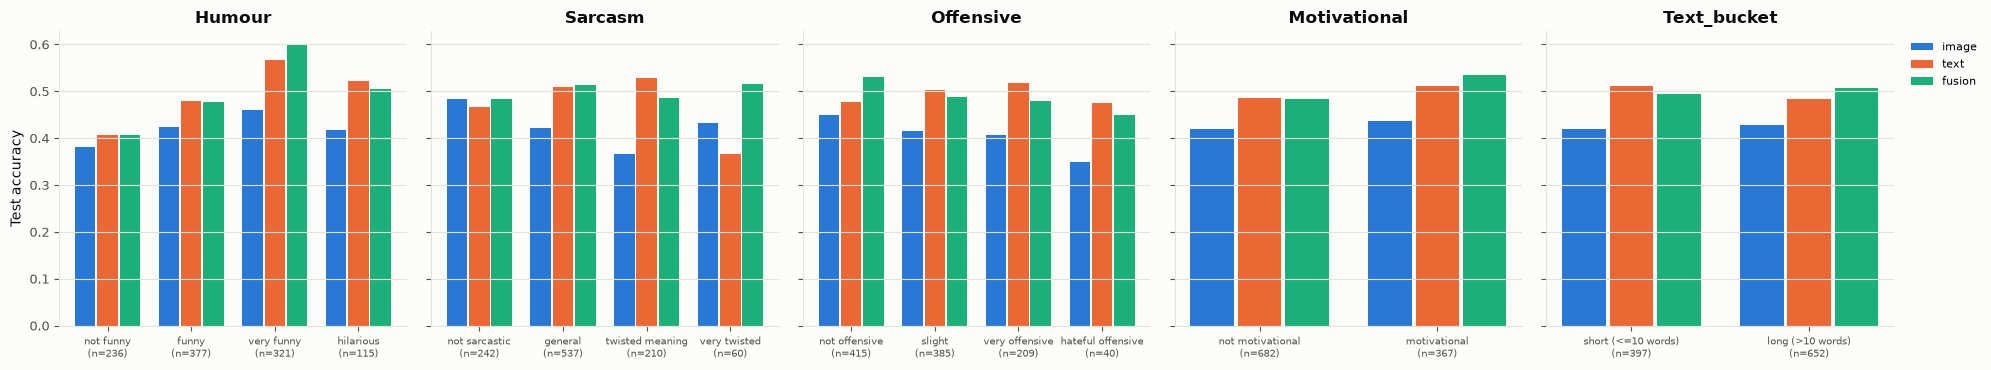

,n,acc
with_near_dup_in_train,12.0,0.583
no_near_dup,1037.0,0.500


In [19]:
df_te["text_bucket"] = np.select([df_te["text_source"] == "placeholder", df_te["n_words"] <= 10],
                                 ["no text", "short (<=10 words)"], "long (>10 words)")
groups = {**D.AUX_ORDERS, "text_bucket": ["no text", "short (<=10 words)", "long (>10 words)"]}
SUB = E.subgroup_table(df_te, {"image": pred["Image only (CLIP)"], "text": pred["Text only (CLIP)"],
                               "fusion": pred[BEST_FUSION]}, groups)
display(SUB)
SUB.to_csv(cfg.table_dir / "subgroups.csv", index=False)
P.plot_subgroups(SUB, ["image", "text", "fusion"], cfg.fig_dir / "fig10_subgroups.png", metric="acc"); plt.show()

# near-duplicate subset
nd = ND["mask"]
ND_PERF = {"with_near_dup_in_train": {"n": int(nd.sum()), "acc": float((pred[BEST_FUSION][nd] == y_te[nd]).mean()) if nd.any() else np.nan},
           "no_near_dup": {"n": int((~nd).sum()), "acc": float((pred[BEST_FUSION][~nd] == y_te[~nd]).mean())}}
display(pd.DataFrame(ND_PERF).T)

### 7.2 Representation view (t-SNE)

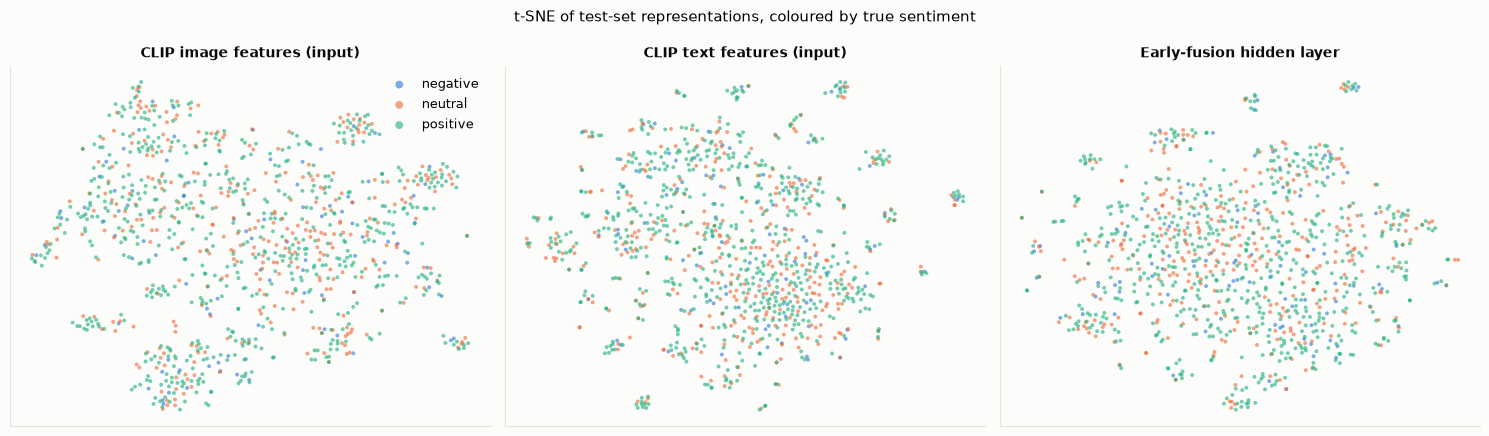

In [20]:
fused_hidden = M.hidden_repr(PROBA["Early fusion (concat)"]["model"], [IMG[2], TXT[2]], cfg)
P.plot_tsne({"CLIP image features (input)": img_all[te.values],
             "CLIP text features (input)": txt_all[te.values],
             "Early-fusion hidden layer": fused_hidden},
            y_te, CLASSES, cfg.fig_dir / "fig11_tsne.png"); plt.show()

### 7.3 Failure cases
The most confident mistakes of the best fusion model. **Check these images before putting the figure in
the report or slides - some memes in the dataset are offensive.**

pred,negative,neutral,positive
label,,,
negative,0,24,66
neutral,23,0,196
positive,34,180,0


,image_name,text,sentiment,pred,conf,sarcasm,offensive
1039,image_6948.jpg,leave the gun take the cheerios mc godfather85,positive,0,0.993,general,very_offensive
374,image_2578.jpg,if you think patience is a virtue try sufferin...,negative,2,0.979,twisted_meaning,not_offensive
770,image_5135.jpeg,it just stopped working? and the last thing yo...,negative,2,0.978,general,slight
820,image_5486.png,html head meta content text html charset utf 8...,neutral,2,0.976,general,very_offensive
421,image_2816.jpg,what if i told you i knew you'd reply late.. j...,neutral,2,0.974,not_sarcastic,not_offensive
695,image_4506.jpg,me battlefield 1 infinite warfare,neutral,2,0.974,general,slight
865,image_5801.png,facebook was a mistake. mark zuckerberg,negative,2,0.974,twisted_meaning,slight
492,image_3171.png,even the sun is against me my dudes pepe pepem...,neutral,0,0.972,not_sarcastic,not_offensive
420,image_2814.jpg,the rock what if i told you you can like marve...,positive,1,0.972,general,not_offensive
181,image_1289.jpeg,when your best friends make fun of your skills...,negative,2,0.971,general,slight


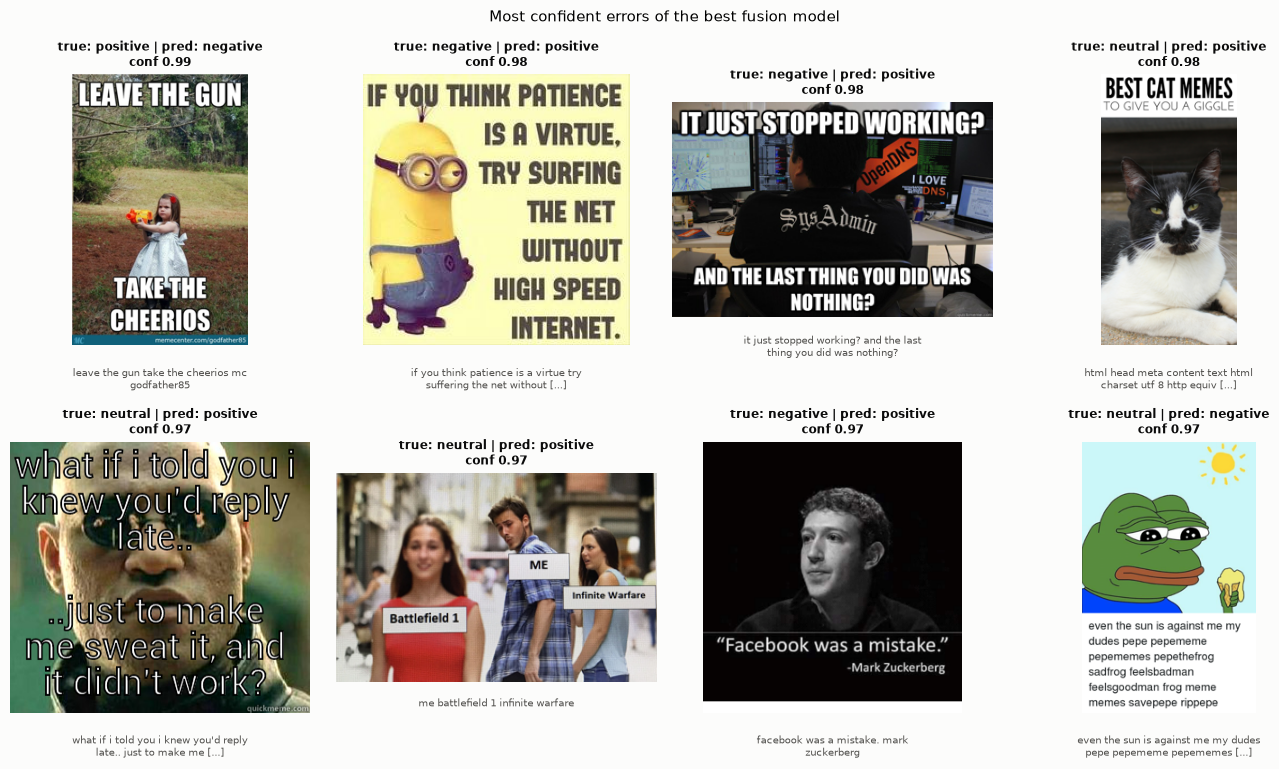

In [21]:
p_best = PROBA[BEST_FUSION][s0]["test"]
cases = df_te.assign(pred=p_best.argmax(1), conf=p_best.max(1))
cases = cases[cases["pred"] != cases["label"]].sort_values("conf", ascending=False)
ERR = pd.crosstab(cases["label"].map(dict(enumerate(CLASSES))), cases["pred"].map(dict(enumerate(CLASSES))))
display(ERR)
display(cases[["image_name", "text", "sentiment", "pred", "conf", "sarcasm", "offensive"]].head(10))
cases[["image_name", "text", "sentiment", "pred", "conf", "humour", "sarcasm", "offensive", "motivational"]].to_csv(
    cfg.table_dir / "errors_best_fusion.csv", index=False)
P.plot_failure_cases(cases, D.load_image, CLASSES, cfg.fig_dir / "fig12_failure_cases.png"); plt.show()

## 8. Save everything for the report

In [22]:
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, pd.DataFrame): return json.loads(o.to_json(orient="index"))
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    return o

RESULTS = {
    "config": cfg.to_dict(), "environment": ENV, "device": DEVICE,
    "data_quality": QUALITY, "removed_unreadable": REMOVED_UNREADABLE, "n_used": len(df),
    "split_counts": split_tab, "near_duplicates": {k: v for k, v in ND.items() if k not in ("mask", "nn_idx", "nn_sim")},
    "near_dup_performance": ND_PERF,
    "test_summary": SUMMARY, "val_summary": VAL_SUMMARY,
    "best_fusion": BEST_FUSION, "best_early_fusion": BEST_EF, "best_late_fusion": BEST_LF,
    "best_attention_fusion": BEST_AF, "attention_weights": ATT_SUMMARY, "uncertainty": UNC,
    "late_fusion_weights": LF_W, "logreg": LR_INFO,
    "bootstrap_ci_seed0": CI, "mcnemar": TESTS, "paired_seed_diffs": PAIRED,
    "overfitting": OVERFIT, "ablation": ABL, "modality_removal": ABL_REMOVE,
    "efficiency": EFF, "feature_seconds": TIMINGS, "encoder_params": ENC_PARAMS,
    "subgroups": SUB.to_dict("records"), "error_matrix": ERR,
}
(cfg.out / "results_summary.json").write_text(json.dumps(jsonable(RESULTS), indent=1))

zip_src = Path("outputs_for_report")
if zip_src.exists():
    shutil.rmtree(zip_src)
shutil.copytree(cfg.fig_dir, zip_src / "figures")
shutil.copytree(cfg.table_dir, zip_src / "tables")
shutil.copy(cfg.out / "results_summary.json", zip_src / "results_summary.json")
shutil.make_archive("outputs_for_report", "zip", zip_src)
shutil.rmtree(zip_src)
print("Saved outputs/ and outputs_for_report.zip")

Saved outputs/ and outputs_for_report.zip
